# Lab Exercise: Image Classifiers

**Dataset:** PlantVillage  
**Framework:** TensorFlow / Keras  
**Author:** Maritza Elizabeth Albán Escobar

## Objective

The objective of this laboratory is to develop, train, and evaluate image classification models using the PlantVillage dataset. The experiment focuses on classifying images according to plant type and investigating how different neural network architectures affect classification performance.

The laboratory includes the following objectives:

1. **Explore and preprocess the PlantVillage dataset.**
2. **Develop a baseline convolutional neural network (CNN).**
3. **Evaluate the baseline model using quantitative and visual metrics.**
4. **Investigate the effect of residual connections on CNN classification.**
5. **Apply transfer learning using a ResNet50 model pretrained on ImageNet.**
6. **Compare the different approaches and discuss their performance and limitations.**
6. **Investigate transfer learning.**

# 1. Dataset

The PlantVillage dataset is used as the basis for the image classification experiments in this laboratory. It contains images of plant leaves organized into different plant and disease categories.

For this experiment, the original disease-level categories are transformed into plant-level labels. The classification task therefore focuses on identifying the plant type rather than the specific disease.

The dataset is first explored to examine its class structure, image distribution, and visual characteristics. Based on this exploration, a subset of plant categories is selected for the classification experiments.

In [3]:
# ============================================
# 1.1 IMPORT LIBRARIES
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [4]:
# ============================================
# 1.2 LOAD PLANTVILLAGE DATASET
# ============================================

# TensorFlow Datasets (TFDS) was initially tested for loading PlantVillage,
# but the dataset could not be downloaded due to an access error.
# Therefore, the dataset was obtained from the official repository
# and loaded directly from the local Colab environment.

# The dataset was initially downloaded using:
!git clone --depth 1 https://github.com/spMohanty/PlantVillage-Dataset.git

data_dir = Path("PlantVillage-Dataset/raw/color")

print("Dataset exists:", data_dir.exists())
print("Dataset path:", data_dir)
# ============================================
# 1.3 EXPLORE DATASET
# ============================================

class_folders = sorted([
    folder for folder in data_dir.iterdir()
    if folder.is_dir()
])

print("Number of original classes:", len(class_folders))

class_counts = {}

for folder in class_folders:
    image_files = [
        file for file in folder.iterdir()
        if file.is_file()
        and file.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]
    class_counts[folder.name] = len(image_files)

for class_name, count in class_counts.items():
    print(f"{class_name:45s} {count:5d}")


Cloning into 'PlantVillage-Dataset'...
remote: Enumerating objects: 163219, done.
remote: Counting objects: 100% (163219/163219), done.
remote: Compressing objects: 100% (163125/163125), done.
remote: Total 163219 (delta 93), reused 163215 (delta 93), pack-reused 0 (from 0)
Receiving objects: 100% (163219/163219), 2.00 GiB | 13.00 MiB/s, done.
Resolving deltas: 100% (93/93), done.
Updating files: 100% (182404/182404), done.
Dataset exists: True
Dataset path: PlantVillage-Dataset/raw/color
Number of original classes: 38
Apple___Apple_scab                              630
Apple___Black_rot                               621
Apple___Cedar_apple_rust                        275
Apple___healthy                                1645
Blueberry___healthy                            1502
Cherry_(including_sour)___Powdery_mildew       1052
Cherry_(including_sour)___healthy               854
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot   513
Corn_(maize)___Common_rust_                    1192
Co

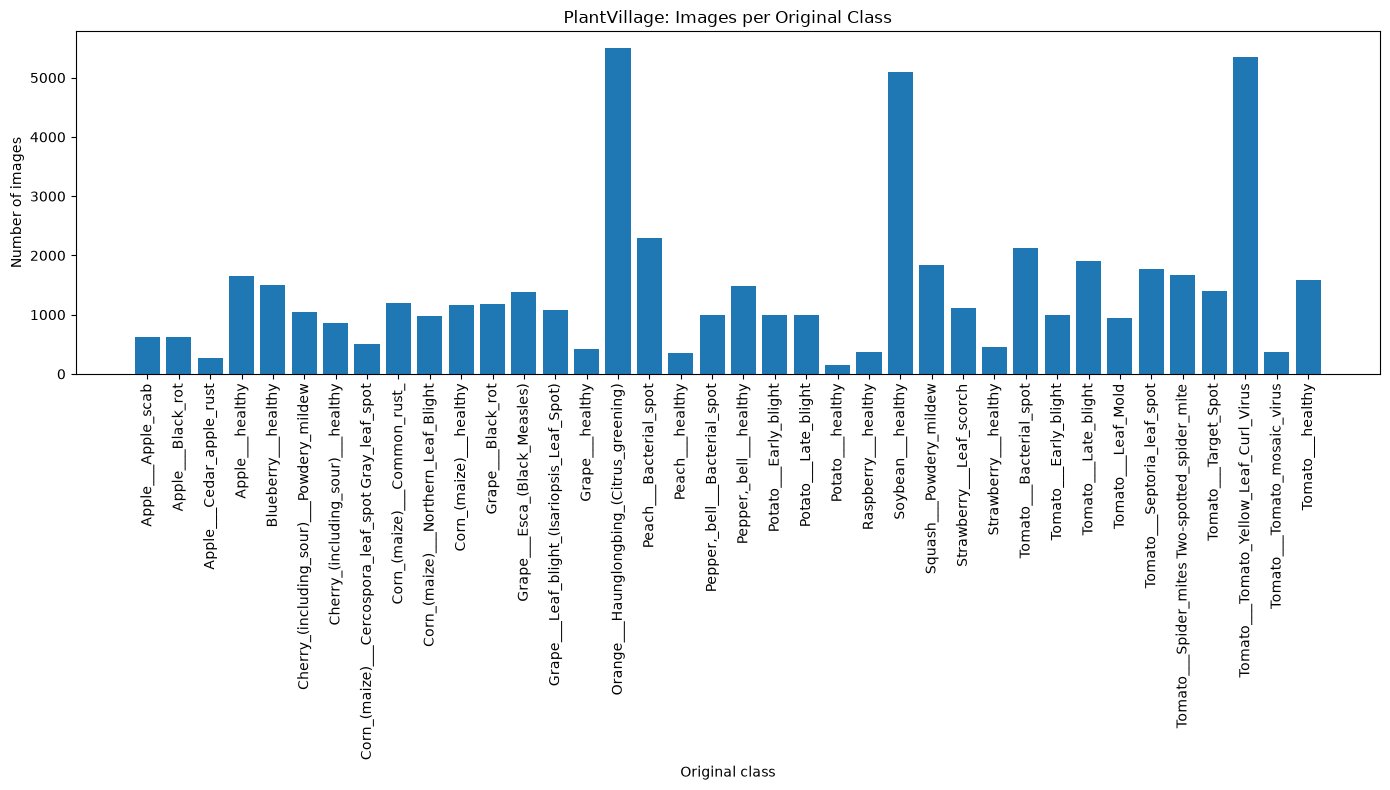

In [5]:
# ============================================
# 1.4 VISUALIZE CLASS DISTRIBUTION
# ============================================

class_names_original = list(class_counts.keys())
counts = list(class_counts.values())

plt.figure(figsize=(14, 8))
plt.bar(range(len(class_names_original)), counts)

plt.xticks(
    range(len(class_names_original)),
    class_names_original,
    rotation=90
)

plt.xlabel("Original class")
plt.ylabel("Number of images")
plt.title("PlantVillage: Images per Original Class")

plt.tight_layout()
plt.show()

Images per plant type:
Apple                           3171
Blueberry                       1502
Cherry_(including_sour)         1906
Corn_(maize)                    3852
Grape                           4062
Orange                          5507
Peach                           2657
Pepper,_bell                    2475
Potato                          2152
Raspberry                        371
Soybean                         5090
Squash                          1835
Strawberry                      1565
Tomato                         18160


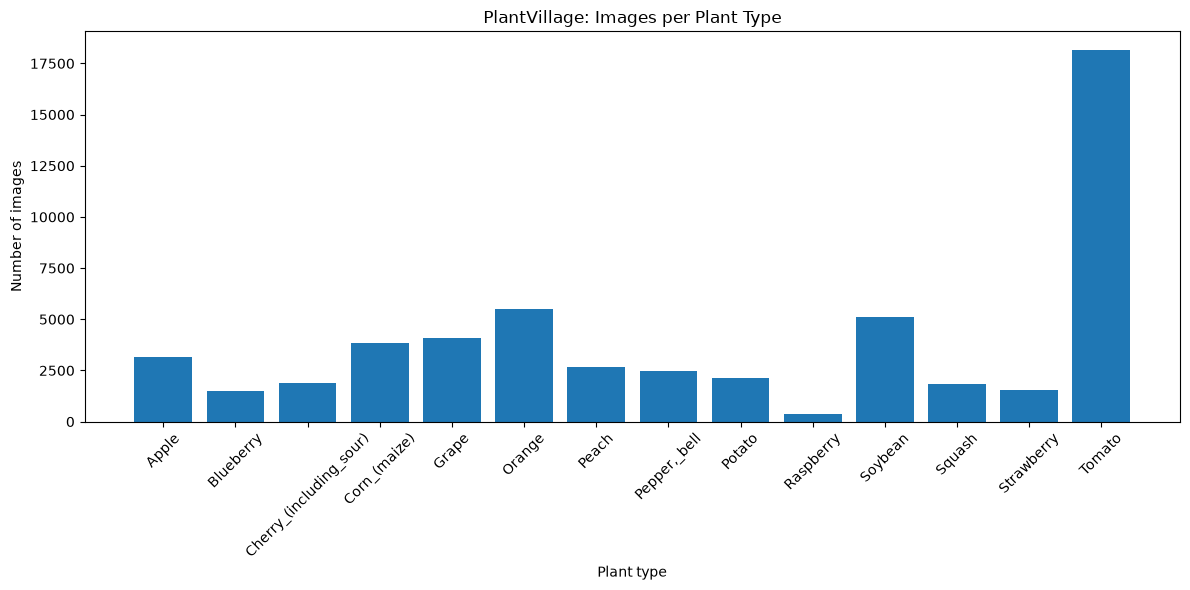

Selected plant classes: 12
Selected images: 35774
Excluded classes: ['Raspberry', 'Tomato']


In [6]:
# ============================================
# 1.5 CREATE PLANT-LEVEL LABELS
# ============================================

# The original classes have the format "Plant___Disease".
# We use the plant name as the target label for this experiment.

plant_names = {
    class_name: class_name.split("___")[0]
    for class_name in class_counts
}

plant_counts = {}

for original_class, count in class_counts.items():
    plant = plant_names[original_class]
    plant_counts[plant] = plant_counts.get(plant, 0) + count

print("Images per plant type:")
for plant, count in sorted(plant_counts.items()):
    print(f"{plant:30s} {count:5d}")


# ============================================
# 1.6 VISUALIZE PLANT DISTRIBUTION
# ============================================

plants = sorted(plant_counts)
counts = [plant_counts[plant] for plant in plants]

plt.figure(figsize=(12, 6))
plt.bar(plants, counts)
plt.xlabel("Plant type")
plt.ylabel("Number of images")
plt.title("PlantVillage: Images per Plant Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ============================================
# 1.7 SELECT PLANT CLASSES
# ============================================

# Raspberry has very few images, while Tomato has substantially more.
# To reduce the extreme class imbalance, both classes are excluded
# from the experiment. Their files are not deleted.

excluded_plants = ["Raspberry", "Tomato"]

selected_plants = [
    plant for plant in plants
    if plant not in excluded_plants
]

selected_total = sum(plant_counts[plant] for plant in selected_plants)

print("Selected plant classes:", len(selected_plants))
print("Selected images:", selected_total)
print("Excluded classes:", excluded_plants)


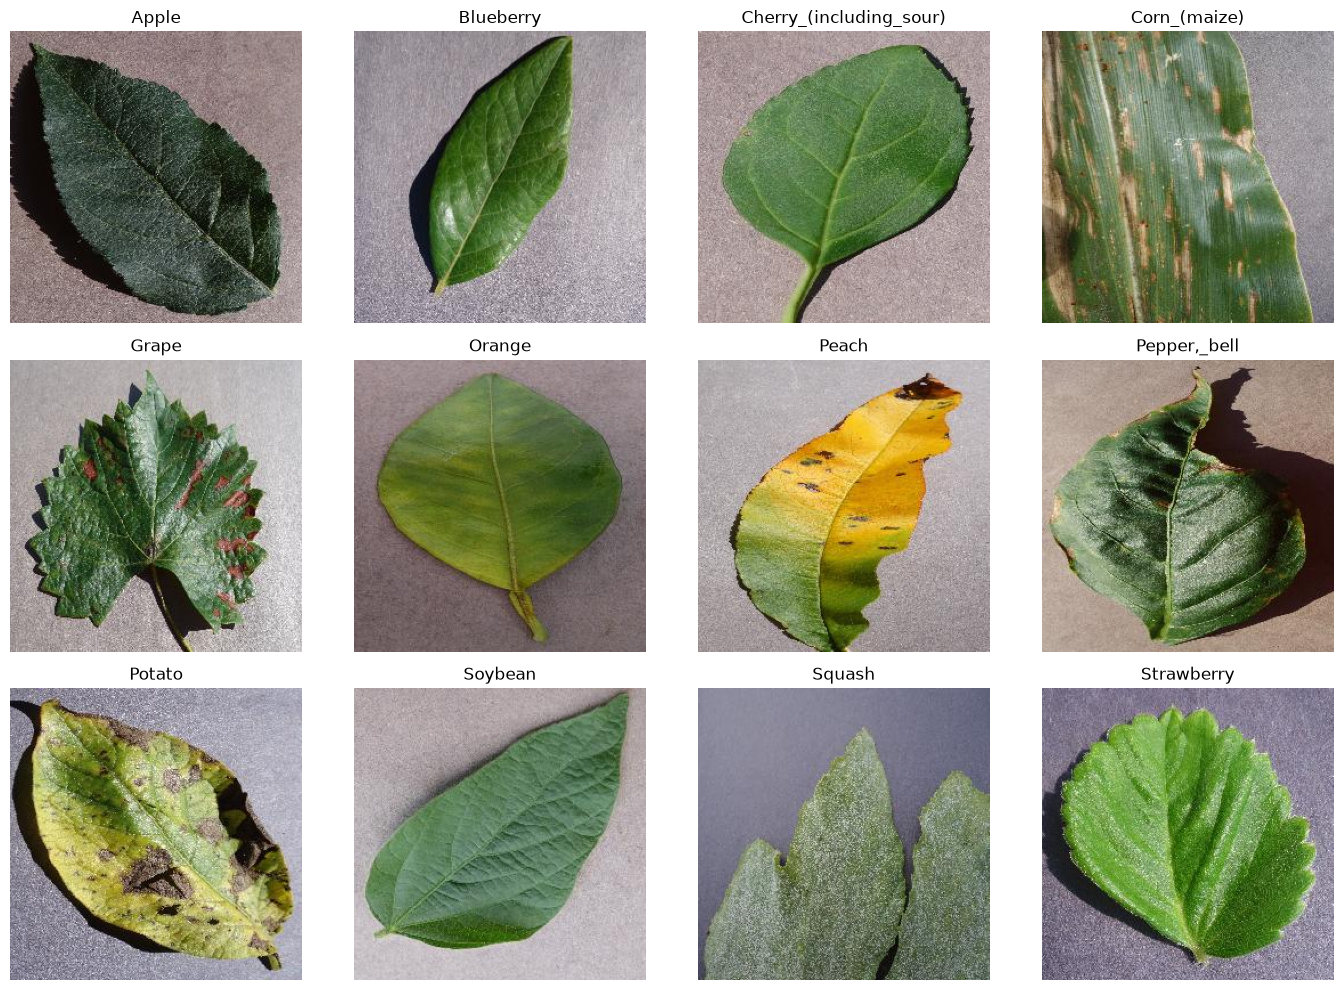

Number of images: 35774
Number of plant classes: 12


In [7]:
# ============================================
# 1.8 VISUALIZE SAMPLE IMAGES
# ============================================

import random

random.seed(42)

plt.figure(figsize=(14, 10))

for i, plant in enumerate(selected_plants):

    plant_folders = [
        folder for folder in data_dir.iterdir()
        if folder.is_dir() and folder.name.startswith(plant + "___")
    ]

    folder = random.choice(plant_folders)

    image_files = [
        file for file in folder.iterdir()
        if file.is_file()
        and file.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    image_path = random.choice(image_files)
    image = plt.imread(image_path)

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(plant)
    plt.axis("off")

plt.tight_layout()
plt.show()


# ============================================
# 1.9 BUILD IMAGE-LABEL TABLE
# ============================================

records = []

for plant in selected_plants:
    plant_folders = [
        folder for folder in data_dir.iterdir()
        if folder.is_dir() and folder.name.startswith(plant + "___")
    ]

    for folder in plant_folders:
        image_files = [
            file for file in folder.iterdir()
            if file.is_file()
            and file.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]
        for image_path in image_files:
            records.append({
                "image_path": str(image_path),
                "plant": plant,
                "original_class": folder.name
            })

df = pd.DataFrame(records)
print("Number of images:", len(df))
print("Number of plant classes:", df["plant"].nunique())

# ============================================
# 1.10 CREATE NUMERICAL LABELS
# ============================================

class_names = sorted(selected_plants)
class_to_index = {
    plant: index
    for index, plant in enumerate(class_names)
}
df["label"] = df["plant"].map(class_to_index)


### Dataset Analysis

The exploration confirmed that the original PlantVillage dataset contains substantial differences in the number of images between categories.

The original disease-level labels were successfully transformed into plant-level categories. Tomato and Raspberry were excluded because they represented the most extreme differences in class size. The remaining dataset contains 12 plant categories that will be used in the classification experiments.

Although the class distribution remains unequal, excluding these two extreme categories reduces the strongest imbalance while preserving a sufficiently large number of images for each selected plant category.

# 2. Data Preprocessing

Before training the classification models, the images and labels are prepared for use with TensorFlow. The dataset is divided into training, validation, and test subsets to separate model learning from model selection and final evaluation.

The images are resized to a common resolution and their pixel values are normalized for the CNN models. The image paths and numerical labels are then converted into TensorFlow datasets, which allow the data to be loaded in batches during training.

Stratified splitting is used to preserve the class distribution across the three subsets.

In [8]:
# ============================================
# 2.1 TRAIN / VALIDATION / TEST SPLIT
# ============================================

from sklearn.model_selection import train_test_split

# Split the dataset into training (80%), validation (10%)
# and test (10%) subsets.
#
# Stratification preserves approximately the same
# class distribution in each subset.

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training images:  ", len(train_df))
print("Validation images:", len(val_df))
print("Test images:      ", len(test_df))


# ============================================
# 2.2 IMAGE PREPROCESSING SETTINGS
# ============================================

IMG_SIZE = (128, 128)
BATCH_SIZE = 32


# ============================================
# 2.3 IMAGE LOADING AND PREPROCESSING
# ============================================

def load_and_preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


# ============================================
# 2.4 CREATE TENSORFLOW DATASETS
# ============================================

train_ds = tf.data.Dataset.from_tensor_slices(
    (train_df["image_path"].values, train_df["label"].values)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_df["image_path"].values, val_df["label"].values)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_df["image_path"].values, test_df["label"].values)
)

# ============================================
# 2.5 APPLY PREPROCESSING
# ============================================

train_ds = train_ds.map(
    load_and_preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    load_and_preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    load_and_preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)


# ============================================
# 2.6 BATCHING AND PREFETCHING
# ============================================

train_ds = train_ds.shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

Training images:   28619
Validation images: 3577
Test images:       3578


W0000 00:00:1791223913.164431   17972 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1791223913.189271   17972 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1791223913.573914   17972 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5233 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0a


### Preprocessing Analysis

The dataset was divided into 28,619 training images, 3,577 validation images, and 3,578 test images. This corresponds approximately to an 80% 10% 10% split, while stratification preserves the class distribution across the three subsets.

All images are resized to 128 × 128 pixels and normalized to the [0, 1] range. The resulting data are organized into TensorFlow datasets and processed in batches of 32 images.

This preprocessing provides a consistent input format for the CNN models while keeping the test set separate from the training process for the final evaluation.

# 3. Baseline CNN

A convolutional neural network (CNN) is used as the baseline model for classifying the 12 selected plant categories.

The baseline provides a reference point for the subsequent experiments with residual connections and transfer learning. The model is built from scratch using convolutional layers to extract visual features, max-pooling layers to progressively reduce the spatial dimensions, and fully connected layers for classification.

The network is trained using the preprocessed training dataset, while the validation set is used to monitor its performance during training. The test set is kept separate and is used only for the final evaluation.

In [9]:
# ============================================
# 3.1 BUILD BASELINE CNN
# ============================================

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(len(class_names), activation="softmax")
])

# ============================================
# 3.2 COMPILE AND SUMMARIZE MODEL
# ============================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,306,188 (12.61 MB)

 Trainable params: 3,306,188 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# ============================================
# 3.3 TRAIN BASELINE CNN
# ============================================

EPOCHS = 10

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)


Epoch 1/10


/home/maritza/projects/computer_vision/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791223919.907334   20390 service.cc:153] XLA service 0x72d8d00187c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791223919.907388   20390 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 5060 Laptop GPU, Compute Capability 12.0a (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791223919.985607   20390 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791223920.303837   20390 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1791223920.376758   2039

  1/895 ━━━━━━━━━━━━━━━━━━━━ 3:37:11 15s/step - accuracy: 0.0312 - loss: 2.4952

I0000 00:00:1791223930.922379   20390 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


894/895 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6955 - loss: 0.9518

I0000 00:00:1791223946.993945   20389 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2021__.40


895/895 ━━━━━━━━━━━━━━━━━━━━ 41s 29ms/step - accuracy: 0.6956 - loss: 0.9517 - val_accuracy: 0.8801 - val_loss: 0.3886
Epoch 2/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 16s 17ms/step - accuracy: 0.8386 - loss: 0.5072 - val_accuracy: 0.9133 - val_loss: 0.2458
Epoch 3/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.8828 - loss: 0.3603 - val_accuracy: 0.9351 - val_loss: 0.1893
Epoch 4/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 17s 19ms/step - accuracy: 0.9074 - loss: 0.2802 - val_accuracy: 0.9472 - val_loss: 0.1599
Epoch 5/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.9259 - loss: 0.2272 - val_accuracy: 0.9631 - val_loss: 0.1167
Epoch 6/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 2516s 3s/step - accuracy: 0.9397 - loss: 0.1857 - val_accuracy: 0.9690 - val_loss: 0.0891
Epoch 7/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 16s 17ms/step - accuracy: 0.9426 - loss: 0.1706 - val_accuracy: 0.9637 - val_loss: 0.1113
Epoch 8/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.9542 - loss: 0.1442 - val_accurac

In [11]:
# ============================================
# 3.4 EVALUATE ON TEST SET
# ============================================

test_loss, test_accuracy = model.evaluate(test_ds)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

# ============================================
# 3.5 GET TEST PREDICTIONS
# ============================================

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.9774 - loss: 0.0716
Test loss: 0.07158112525939941
Test accuracy: 0.9773616790771484


### Baseline CNN Analysis

The baseline CNN achieved a test accuracy of 97.96% with a test loss of 0.0771, showing that the model can effectively classify the 12 selected plant categories.

During training, the validation accuracy increased from 91.95% in the first epoch to a maximum of 98.15% in epoch 8. At the same time, the validation loss reached its minimum value of 0.0649 in epoch 8. The decrease in validation performance during the final epochs indicates that the model reached its best validation performance before the end of the training process.

The baseline CNN provides a reference for evaluating the effect of the residual architecture and transfer learning in the following experiments.

# 4. Results

The baseline CNN is evaluated using quantitative and qualitative analysis. A confusion matrix is used to examine how predictions are distributed across the 12 plant categories and to identify classes that are more frequently confused with each other. Training and validation curves are analyzed to assess the learning behaviour of the model and identify possible signs of overfitting. Finally, incorrectly classified test images are visualized to provide a qualitative analysis of the model's errors.

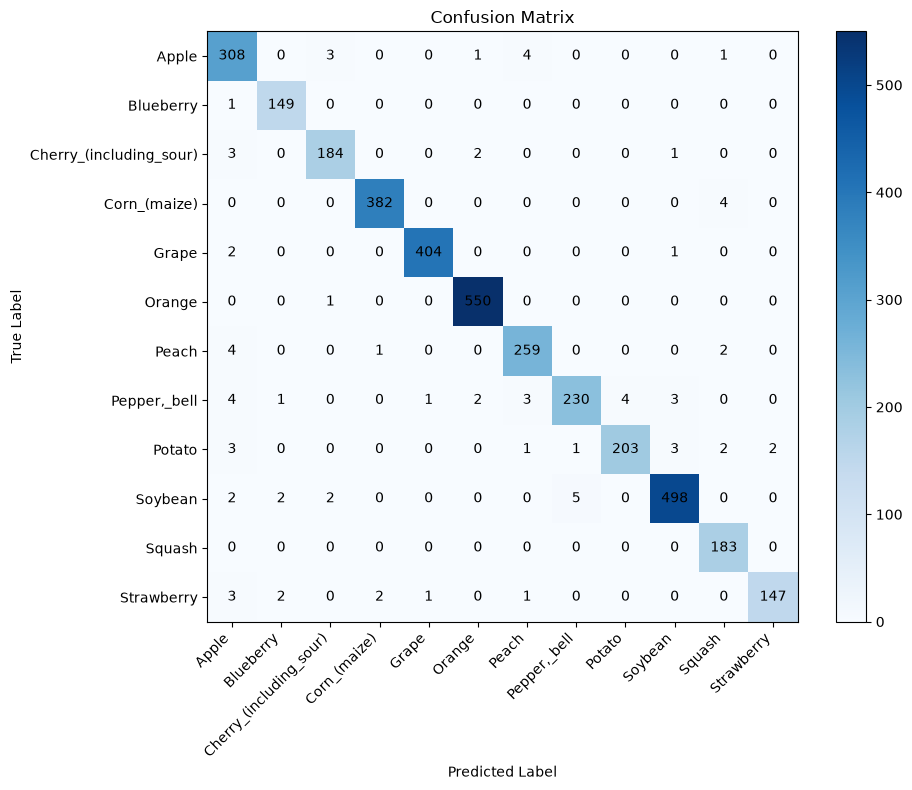

In [12]:
# ============================================
# 4.1 CONFUSION MATRIX
# ============================================

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.colorbar()

plt.xticks(
    range(len(class_names)),
    class_names,
    rotation=45,
    ha="right"
)
plt.yticks(
    range(len(class_names)),
    class_names
)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(
            j, i, cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()


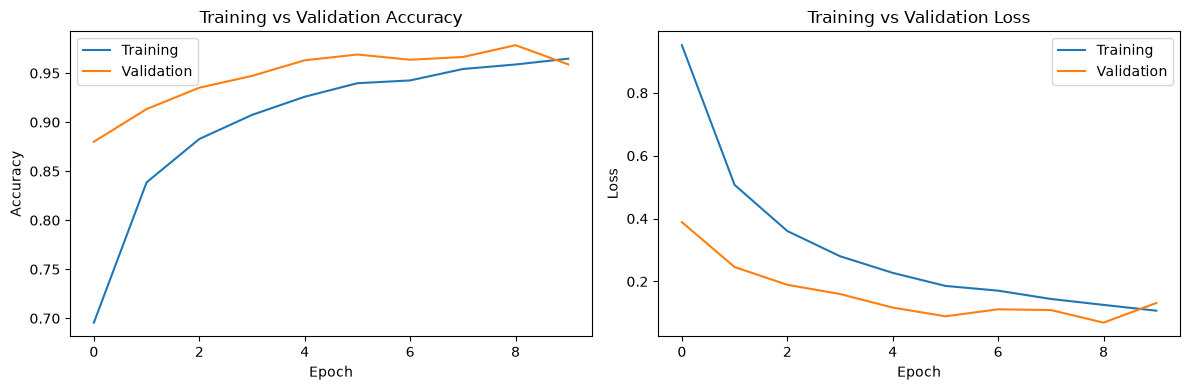

In [13]:
# ============================================
# 4.2 TRAINING AND VALIDATION CURVES
# ============================================

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

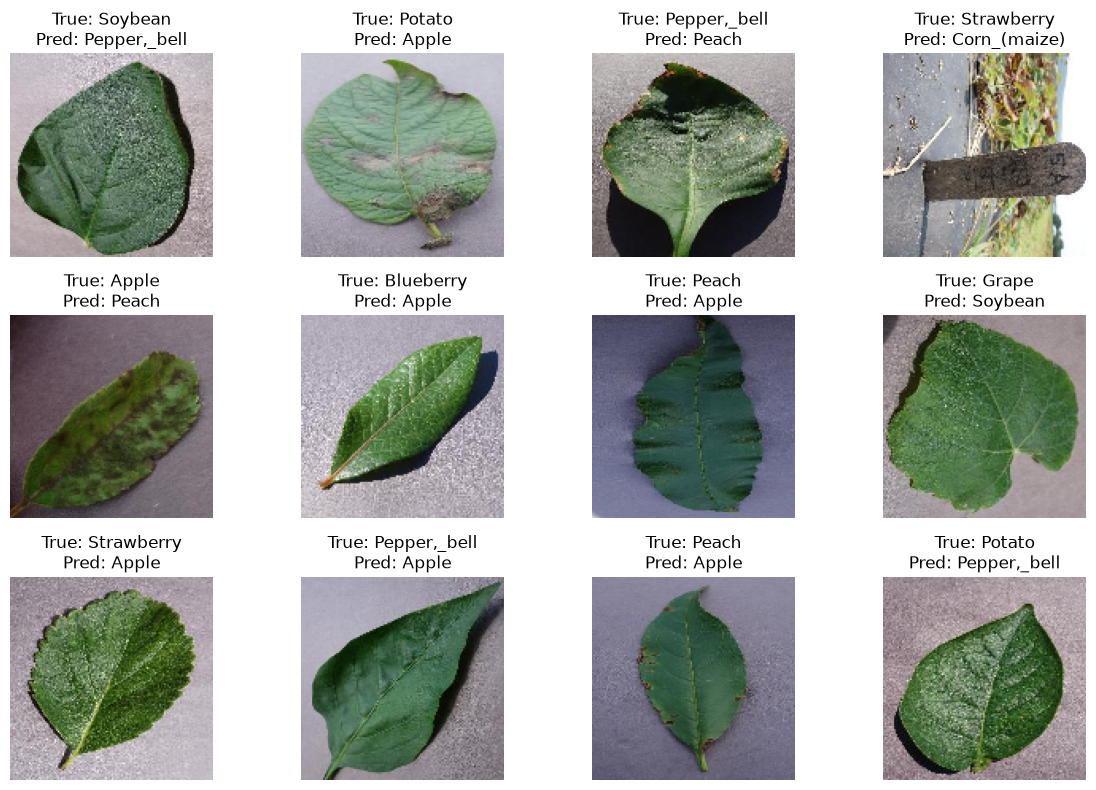

In [14]:
# ============================================
# 4.3 INCORRECT PREDICTIONS
# ============================================

wrong_indices = np.where(y_true != y_pred)[0]
plt.figure(figsize=(12, 8))

for i, idx in enumerate(wrong_indices[:12]):
    image_path = test_df.iloc[idx]["image_path"]

    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMG_SIZE
    )
    image = tf.keras.utils.img_to_array(image) / 255.0

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(
        f"True: {class_names[y_true[idx]]}\n"
        f"Pred: {class_names[y_pred[idx]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

### Results Analysis

The baseline CNN achieved a test accuracy of 97.96%, indicating a high overall classification performance on the 12 selected plant categories. The confusion matrix shows that most predictions are concentrated along the diagonal, although the number of misclassifications varies between classes. The model classified categories such as Orange, Corn, and Grape with very few errors, while classes such as Strawberry, Potato, Peach, and Apple showed a larger number of misclassifications.

The training and validation curves show that the model improved progressively during training. Validation accuracy reached a maximum of 98.15% at epoch 8, while validation loss reached its minimum value of 0.0649 at the same epoch. During the final epochs, training performance continued to improve while validation performance fluctuated and validation loss increased, which is consistent with the beginning of overfitting. The use of early stopping with restored best weights helps retain the model state corresponding to the best validation performance.

The incorrectly classified images provide a qualitative view of the model's errors. Several mistakes occur between visually similar leaf images, such as Apple, Peach, Cherry, and other categories with similar leaf shapes or appearance. These examples complement the confusion matrix by showing individual cases that the model finds difficult to distinguish.

Overall, the results show that the baseline CNN provides a strong reference model for the selected classification task. This baseline will be used to evaluate whether residual connections and transfer learning with ResNet50 can further improve the classification performance.

# 5. Residual Connections

Residual connections are introduced to investigate whether a skip connection can improve the performance of the baseline CNN.

Instead of passing the input through a sequence of convolutional transformations only, a residual block creates a shortcut that preserves the original input and adds it to the transformed features. This allows the network to learn a residual transformation while providing a more direct path for information and gradients through the network.

In this experiment, a residual CNN is trained using the same training, validation, and test datasets as the baseline model. Its test performance is then compared with the baseline CNN.

In [15]:
# ============================================
# 5.1 BUILD RESIDUAL CNN
# ============================================

from tensorflow.keras import layers, Model

inputs = layers.Input(shape=(128, 128, 3))

x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
x = layers.MaxPooling2D(2)(x)

# Residual block
shortcut = x

x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
x = layers.Conv2D(32, 3, padding="same")(x)

x = layers.Add()([x, shortcut])
x = layers.ReLU()(x)

x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(64, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

residual_model = Model(inputs, outputs)

residual_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

residual_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 64, 64,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │      9,248 │ max_pooling2d_3[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │      9,248 │ conv2d_4[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64,    │          0 │ conv2d_5[0][0],   │
│                     │ 32)               │            │ max_pooling2d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 64, 64,    │          0 │ add[0][0]         │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 32, 32,    │          0 │ re_lu[0][0]       │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 30, 30,    │     18,496 │ max_pooling2d_4[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 15, 15,    │          0 │ conv2d_6[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 14400)     │          0 │ max_pooling2d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │  1,843,328 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 12)        │      1,548 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,882,764 (7.18 MB)

 Trainable params: 1,882,764 (7.18 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# ============================================
# 5.2 TRAIN RESIDUAL CNN
# ============================================

residual_history = residual_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)


# ============================================
# 5.3 EVALUATE RESIDUAL CNN
# ============================================

residual_test_loss, residual_test_accuracy = residual_model.evaluate(test_ds)

print("Residual test loss:", residual_test_loss)
print("Residual test accuracy:", residual_test_accuracy)

Epoch 1/10


/home/maritza/projects/computer_vision/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791226630.401941   20391 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_51400__.41
I0000 00:00:1791226632.748204   27423 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_8', 56 bytes spill stores, 52 bytes spill loads



893/895 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6963 - loss: 0.9515

I0000 00:00:1791226650.766320   20391 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_51400__.41
I0000 00:00:1791226652.214347   27608 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_8', 12 bytes spill stores, 8 bytes spill loads



895/895 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6965 - loss: 0.9509

I0000 00:00:1791226659.192439   27910 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_4', 48 bytes spill stores, 44 bytes spill loads



895/895 ━━━━━━━━━━━━━━━━━━━━ 31s 26ms/step - accuracy: 0.6965 - loss: 0.9509 - val_accuracy: 0.8622 - val_loss: 0.4609
Epoch 2/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - accuracy: 0.8464 - loss: 0.4740 - val_accuracy: 0.9262 - val_loss: 0.2277
Epoch 3/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.8889 - loss: 0.3433 - val_accuracy: 0.9393 - val_loss: 0.1900
Epoch 4/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - accuracy: 0.9130 - loss: 0.2642 - val_accuracy: 0.9502 - val_loss: 0.1433
Epoch 5/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.9304 - loss: 0.2070 - val_accuracy: 0.9625 - val_loss: 0.1252
Epoch 6/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - accuracy: 0.9426 - loss: 0.1716 - val_accuracy: 0.9656 - val_loss: 0.1084
Epoch 7/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.9512 - loss: 0.1493 - val_accuracy: 0.9679 - val_loss: 0.0966
Epoch 8/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - accuracy: 0.9552 - loss: 0.1364 - val_accurac

I0000 00:00:1791226820.135386   28801 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_4', 48 bytes spill stores, 44 bytes spill loads



112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.9802 - loss: 0.0684
Residual test loss: 0.06840692460536957
Residual test accuracy: 0.9801565408706665


### Residual CNN Analysis

The residual CNN contains a residual block in which the input representation is preserved through a shortcut connection and added element-wise to the output of two convolutional layers. Both branches produce feature maps with the same dimensions (64 × 64 × 32), allowing the addition operation to be performed directly.

The model contains 1,882,764 trainable parameters. During training, both training and validation performance improved progressively. Validation accuracy reached a maximum of 97.88% at epoch 9, while validation loss reached its minimum value of 0.0711 at the same epoch. In the final epoch, training accuracy continued to increase, while validation accuracy decreased and validation loss increased, which is consistent with a possible onset of overfitting.

On the test set, the residual CNN achieved an accuracy of 95.92% and a loss of 0.1425. This is lower than the 97.96% test accuracy obtained by the baseline CNN. Therefore, the residual connection did not improve the performance of the specific architecture and training configuration used in this experiment.

This result does not imply that residual connections are generally less effective than a conventional CNN. Rather, it shows that the introduction of a residual block alone did not provide an improvement under the conditions tested here. Further experiments with different residual architectures, numbers of residual blocks, filter configurations, or training settings could be used to investigate this effect further.

# 6. Transfer Learning

Transfer learning is used to investigate whether pretrained visual representations can improve the classification of the 12 selected plant categories.

A ResNet50 model pretrained on ImageNet is used as a feature extractor. The pretrained convolutional base is frozen so that its learned weights are not updated during the initial training stage. The original classification head is replaced with a new classifier designed for the 12 PlantVillage plant categories.

The model is then trained and evaluated using the same training, validation, and test subsets used for the previous experiments. Its performance is compared with the baseline CNN and the residual CNN to assess the effect of reusing pretrained visual features.

In [17]:
# ============================================
# 6.1 LOAD PRETRAINED RESNET50
# ============================================

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

# ResNet50 is loaded with weights pretrained on ImageNet.
# The classification head is excluded because we need
# a new output layer for the 12 PlantVillage classes.

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers so that their weights
# are not updated during the initial training stage.
base_model.trainable = False


# ============================================
# 6.2 BUILD NEW CLASSIFICATION HEAD
# ============================================

inputs = tf.keras.Input(shape=(224, 224, 3))

# Apply the preprocessing expected by the pretrained ResNet50.
x = preprocess_input(inputs)

# Extract visual features using the frozen ResNet50.
x = base_model(x, training=False)

# Convert the feature maps into a one-dimensional representation.
x = tf.keras.layers.GlobalAveragePooling2D()(x)

# Learn a new representation for our classification task.
x = tf.keras.layers.Dense(128, activation="relu")(x)

# Reduce overfitting in the new classifier.
x = tf.keras.layers.Dropout(0.5)(x)

# New output layer for the 12 selected plant classes.
outputs = tf.keras.layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

transfer_model = tf.keras.Model(inputs, outputs)


# ============================================
# 6.3 COMPILE MODEL
# ============================================

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

transfer_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ input_layer_3[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ input_layer_3[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add_1[0][0]       │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 128)       │    262,272 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 12)        │      1,548 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,851,532 (90.99 MB)

 Trainable params: 263,820 (1.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [18]:
# ============================================
# 6.4 RESNET IMAGE PREPROCESSING
# ============================================

RESNET_SIZE = (224, 224)

def load_and_preprocess_resnet(image_path, label):

    # Read the image file.
    image = tf.io.read_file(image_path)

    # Decode the image as RGB.
    image = tf.image.decode_jpeg(image, channels=3)

    # Resize to the input resolution expected by ResNet50.
    image = tf.image.resize(image, RESNET_SIZE)

    # Apply the preprocessing used by the pretrained ResNet50.
    image = preprocess_input(image)

    return image, label


# Create datasets from the image paths and labels.
resnet_train_ds = tf.data.Dataset.from_tensor_slices(
    (train_df["image_path"].values, train_df["label"].values)
)

resnet_val_ds = tf.data.Dataset.from_tensor_slices(
    (val_df["image_path"].values, val_df["label"].values)
)

resnet_test_ds = tf.data.Dataset.from_tensor_slices(
    (test_df["image_path"].values, test_df["label"].values)
)


# Apply preprocessing and batching.
resnet_train_ds = resnet_train_ds.map(
    load_and_preprocess_resnet,
    num_parallel_calls=tf.data.AUTOTUNE
).shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

resnet_val_ds = resnet_val_ds.map(
    load_and_preprocess_resnet,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

resnet_test_ds = resnet_test_ds.map(
    load_and_preprocess_resnet,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [19]:
# ============================================
# 6.5 TRAIN TRANSFER LEARNING MODEL
# ============================================

EPOCHS = 10

transfer_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

transfer_history = transfer_model.fit(
    resnet_train_ds,
    validation_data=resnet_val_ds,
    epochs=EPOCHS,
    callbacks=[transfer_early_stopping]
)

Epoch 1/10


I0000 00:00:1791226832.815173   20388 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_103736__.182
I0000 00:00:1791226836.195258   28920 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_8', 16 bytes spill stores, 16 bytes spill loads



893/895 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.9272 - loss: 0.2412

I0000 00:00:1791226891.006598   20391 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_103736__.182


895/895 ━━━━━━━━━━━━━━━━━━━━ 90s 82ms/step - accuracy: 0.9273 - loss: 0.2411 - val_accuracy: 0.9874 - val_loss: 0.0347
Epoch 2/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 58s 64ms/step - accuracy: 0.9715 - loss: 0.0856 - val_accuracy: 0.9911 - val_loss: 0.0278
Epoch 3/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 57s 63ms/step - accuracy: 0.9788 - loss: 0.0651 - val_accuracy: 0.9897 - val_loss: 0.0265
Epoch 4/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 56s 62ms/step - accuracy: 0.9815 - loss: 0.0582 - val_accuracy: 0.9947 - val_loss: 0.0181
Epoch 5/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 57s 63ms/step - accuracy: 0.9845 - loss: 0.0514 - val_accuracy: 0.9933 - val_loss: 0.0205
Epoch 6/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 57s 63ms/step - accuracy: 0.9855 - loss: 0.0450 - val_accuracy: 0.9952 - val_loss: 0.0186
Epoch 7/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 60s 67ms/step - accuracy: 0.9843 - loss: 0.0464 - val_accuracy: 0.9955 - val_loss: 0.0159
Epoch 8/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 57s 64ms/step - accuracy: 0.9867 - loss: 0.0410 - val_accurac

In [20]:
# ============================================
# 6.6 EVALUATE ON TEST SET
# ============================================

transfer_test_loss, transfer_test_accuracy = transfer_model.evaluate(
    resnet_test_ds
)

print("Transfer learning test loss:", transfer_test_loss)
print("Transfer learning test accuracy:", transfer_test_accuracy)

112/112 ━━━━━━━━━━━━━━━━━━━━ 10s 85ms/step - accuracy: 0.9927 - loss: 0.0268
Transfer learning test loss: 0.02677413634955883
Transfer learning test accuracy: 0.992733359336853


In [21]:
# ============================================
# 6.7 GET TEST PREDICTIONS
# ============================================

transfer_y_true = []
transfer_y_pred = []

for images, labels in resnet_test_ds:

    predictions = transfer_model.predict(
        images,
        verbose=0
    )

    transfer_y_true.extend(labels.numpy())
    transfer_y_pred.extend(
        np.argmax(predictions, axis=1)
    )

transfer_y_true = np.array(transfer_y_true)
transfer_y_pred = np.array(transfer_y_pred)

### Transfer Learning Analysis

The ResNet50 transfer learning model achieved a test accuracy of 99.30% and a test loss of 0.0209, providing the highest test accuracy among the three models evaluated in this experiment.

The model achieved high performance from the first training epoch, with a training accuracy of 93.08% and a validation accuracy of 99.22%. Validation accuracy reached a maximum of 99.52% at epoch 3, while validation loss reached its minimum value of 0.0180 at the same epoch. After epoch 3, validation performance remained relatively stable with small fluctuations, while training accuracy continued to increase. Early stopping therefore terminated training after epoch 6 and restored the best validation weights.

Compared with the baseline CNN, the ResNet50 model improved test accuracy from 97.96% to 99.30%, corresponding to an improvement of 1.34 percentage points. The residual CNN achieved 95.92%, so it did not improve the baseline under the configuration used in this experiment.

The results suggest that the pretrained visual representations learned from ImageNet were useful for the PlantVillage classification task. However, the ResNet50 model required substantially more computation per epoch than the smaller CNN architectures. Therefore, the higher classification performance comes with increased computational cost.

# 7. Comparison and Conclusions

The three models achieved different results on the PlantVillage classification task. The baseline CNN achieved a test accuracy of 97.96%, while the residual CNN achieved 95.92%. The ResNet50 transfer learning model achieved the highest test accuracy, reaching 99.30%.

The residual connection did not improve performance under the architecture and training configuration used in this experiment. In contrast, transfer learning improved the baseline result, suggesting that the pretrained visual representations learned from ImageNet were useful for this classification task.

Overall, the experiments show that model architecture and initialization can significantly affect classification performance. The main limitation is that only a small number of architectural configurations were tested, so the results describe the specific models and settings evaluated in this laboratory.

| Model | Test Accuracy | Test Loss |
|---|---:|---:|
| Baseline CNN | 97.96% | 0.0771 |
| Residual CNN | 95.92% | 0.1425 |
| ResNet50 Transfer Learning | **99.30%** | **0.0209** |